In [ ]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)


Class distribution (0: malignant, 1: benign):
1    0.627417
0    0.372583
Name: proportion, dtype: float64


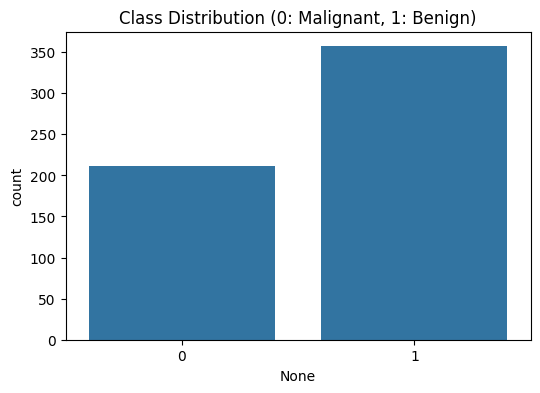

In [ ]:
#EDA: Class distribution
print("\nClass distribution (0: malignant, 1: benign):")
print(y.value_counts(normalize=True))
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Class Distribution (0: Malignant, 1: Benign)")
plt.show()

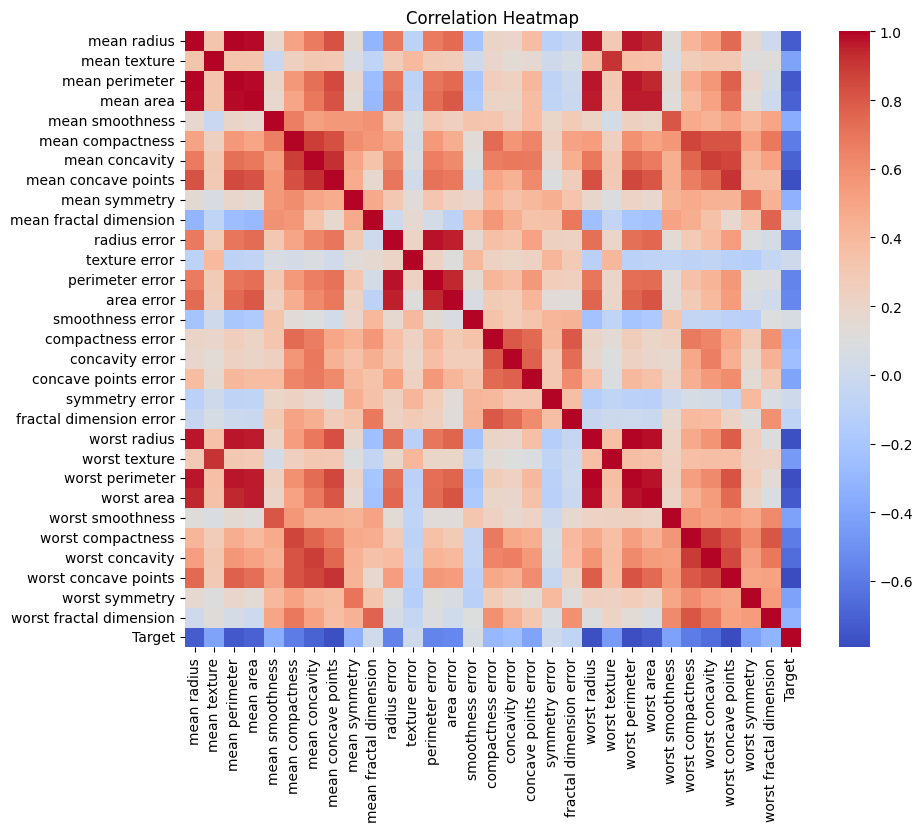

In [ ]:
# EDA: Correlation heatmap
data_temp = X.copy()
data_temp['Target'] = y
corr_matrix = data_temp.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', square=True)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Split into 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Print number of samples
print("Number of training samples:", X_train.shape[0])
print("Number of testing samples:", X_test.shape[0])

Number of training samples: 455
Number of testing samples: 114


In [ ]:
from sklearn.linear_model import LogisticRegression
model_lr = LogisticRegression (random_state=42)
model_lr.fit(X_train, y_train)
print("Coefficients:", model_lr.coef_)
print("Intercept:", model_lr.intercept_)

Coefficients: [[ 1.14431277  0.39807721  0.14704241 -0.00783212 -0.04732694 -0.21461675
  -0.30096654 -0.12506931 -0.08079179 -0.01508592  0.04230194  0.49828934
   0.17585091 -0.11078151 -0.00452854 -0.04771346 -0.06843117 -0.01700302
  -0.01975014 -0.00407675  1.14029404 -0.47540692 -0.17118634 -0.02110969
  -0.08508988 -0.68612625 -0.86067852 -0.24591433 -0.24025011 -0.06559621]]
Intercept: [0.20869427]


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve)
y_pred_lr = model_lr.predict(X_test)
print("Logistic Regression Evaluation Metrics:")
print(f"Accuracy: {accuracy_score (y_test, y_pred_lr):.2f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.2f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr):.2f}")
print(f"ROC AUC: {roc_auc_score(y_test, model_lr.predict_proba (X_test) [:, 1]):.2f}")

Logistic Regression Evaluation Metrics:
Accuracy: 0.96
Precision: 0.95
Recall: 0.99
F1 Score: 0.97
ROC AUC: 0.99


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
# Section 1: Reduce Dimensionality with PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform (X_train)
X_test_pca = pca.transform(X_test)

In [ ]:
model_lr_pca = LogisticRegression().fit(X_train_pca, y_train)

In [ ]:
X_min, X_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(X_min, X_max, 0.5), np.arange(y_min, y_max, 0.5))
Z = model_lr_pca.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

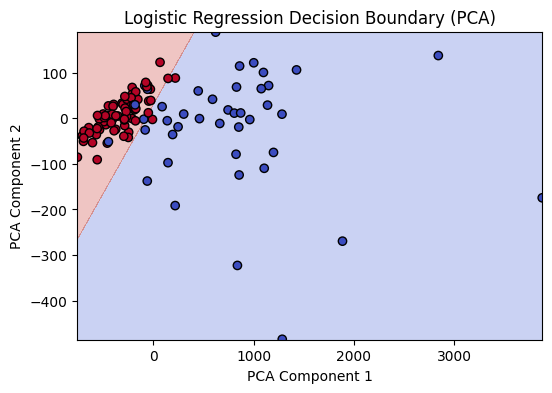

In [ ]:
plt.figure(figsize=(6, 4))
plt.contourf (xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='coolwarm', edgecolors='k')
plt.title("Logistic Regression Decision Boundary (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

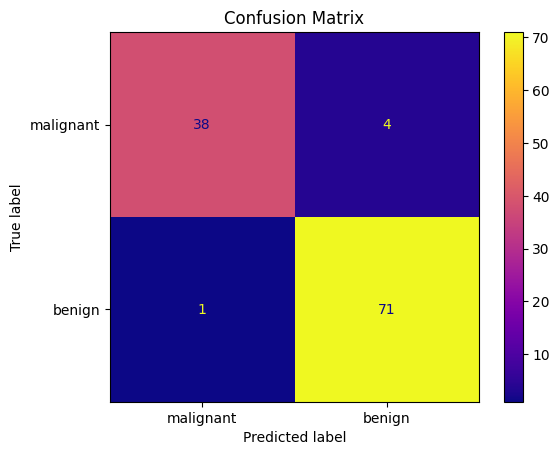

In [ ]:
cm = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay (confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap=plt.cm.plasma)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(X_train, y_train)

KNeighborsClassifier()

In [ ]:
y_pred_knn = model_knn.predict(X_test)
print("\nKNN Metrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.2f}")
print(f"Precision: {precision_score (y_test, y_pred_knn):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_knn):.2f}")
print(f"F1 Score: {f1_score(y_test, y_pred_knn):.2f}")
print (f"ROC AUC: {roc_auc_score(y_test, model_knn.predict_proba (X_test) [:, 1]):.2f}")


KNN Metrics:
Accuracy: 0.91
Precision: 0.94
Recall: 0.92
F1 Score: 0.93
ROC AUC: 0.96


In [ ]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [ ]:
model_knn_pca = KNeighborsClassifier(n_neighbors=5).fit(X_train_pca, y_train)

In [ ]:
x_min, x_max = X_test_pca[:, 0].min() -1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() -1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid (np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))
Z = model_knn_pca.predict(np.c_[xx.ravel(), yy.ravel()]).reshape (xx.shape)

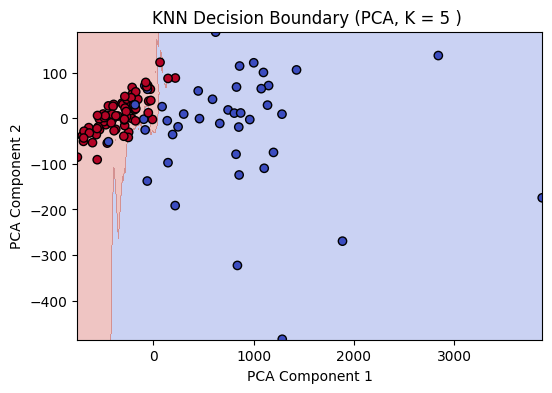

In [ ]:
plt.figure(figsize=(6, 4))
plt.contourf (xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter (X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='coolwarm', edgecolors='k')
plt.title("KNN Decision Boundary (PCA, K = 5 ) ")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

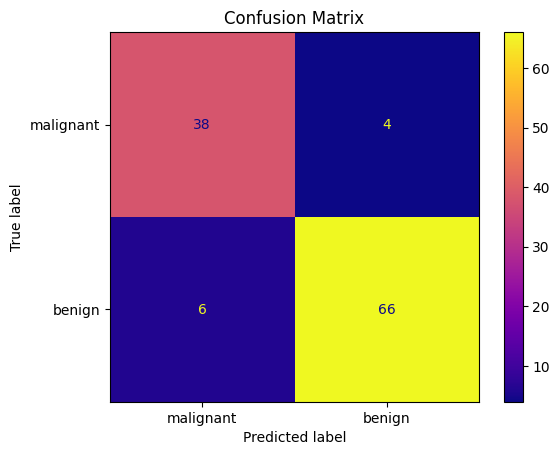

In [ ]:
cm = confusion_matrix(y_test, y_pred_knn)
disp = ConfusionMatrixDisplay (confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap=plt.cm.plasma)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
for k in [1, 5, 10]:
  model_knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
  y_pred_knn = model_knn.predict(X_test)
  print(f"KNN (K={k}) Metrics:")
  print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.2f}, F1: {f1_score(y_test, y_pred_knn):.2f}")

KNN (K=1) Metrics:
Accuracy: 0.92, F1: 0.94
KNN (K=5) Metrics:
Accuracy: 0.91, F1: 0.93
KNN (K=10) Metrics:
Accuracy: 0.93, F1: 0.94


In [ ]:
from sklearn.svm import SVC
for kernel in ['linear', 'rbf']:
  model_svm = SVC(kernel=kernel, probability=True, random_state=42)
  model_svm.fit(X_train, y_train)
  print(f"\n SVM ({kernel}) Support Vectors:", len (model_svm.support_vectors_))


 SVM (linear) Support Vectors: 49

 SVM (rbf) Support Vectors: 124



SVM ((kernel)) Metrics:
Accuracy: 0.96
Precision: 0.95
Recall: 0.99
F1 Score: 0.97
ROC AUC: 1.00

SVM ((kernel)) Metrics:
Accuracy: 0.93
Precision: 0.92
Recall: 0.97
F1 Score: 0.95
ROC AUC: 0.97


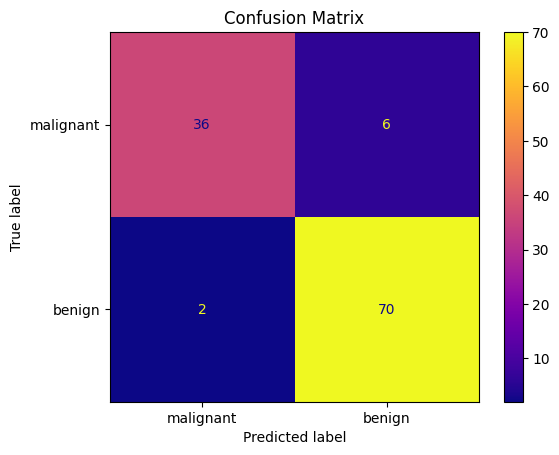

In [ ]:
for kernel in ['linear', 'rbf']:
  model_svm = SVC (kernel=kernel, probability=True, random_state=42).fit(X_train, y_train)
  y_pred_svm = model_svm.predict(X_test)
  print(f"\nSVM ((kernel)) Metrics:")
  print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.2f}")
  print(f"Precision: {precision_score(y_test, y_pred_svm):.2f}")
  print(f"Recall: {recall_score(y_test, y_pred_svm):.2f}")
  print(f"F1 Score: {f1_score (y_test, y_pred_svm):.2f}")
  print(f"ROC AUC: {roc_auc_score(y_test, model_svm.predict_proba (X_test)[:, 1]):.2f}")

cm = confusion_matrix(y_test, y_pred_svm)
disp = ConfusionMatrixDisplay (confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap=plt.cm.plasma)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform (X_train)
X_test_pca = pca.transform(X_test)

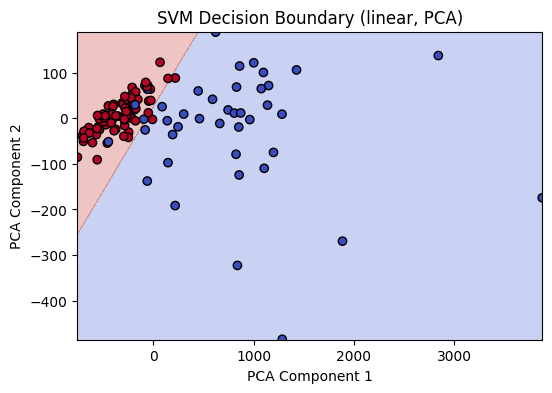

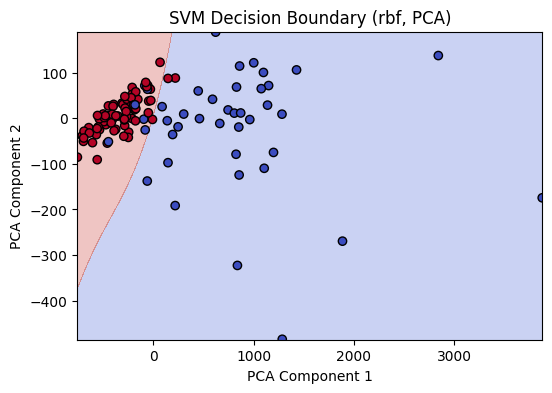

In [ ]:
for kernel in ['linear', 'rbf']:

  model_svm_pca = SVC (kernel=kernel).fit(X_train_pca, y_train)

  x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
  y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))
  Z = model_svm_pca.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

  plt.figure(figsize=(6, 4))
  plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
  plt.scatter (X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='coolwarm', edgecolors='k')
  plt.title(f"SVM Decision Boundary ({kernel}, PCA)")
  plt.xlabel("PCA Component 1")
  plt.ylabel("PCA Component 2")
  plt.show()

In [ ]:
for C in [0.1, 1, 10]:
  model_svm = SVC (kernel='rbf', C=C, probability=True, random_state=42).fit(X_train, y_train)
  y_pred_svm = model_svm.predict(X_test)
  print(f"SVM (RBF, C={C}) Metrics:")
  print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.2f}, F1: {f1_score (y_test, y_pred_svm):.2f}")

SVM (RBF, C=0.1) Metrics:
Accuracy: 0.91, F1: 0.93
SVM (RBF, C=1) Metrics:
Accuracy: 0.93, F1: 0.95
SVM (RBF, C=10) Metrics:
Accuracy: 0.93, F1: 0.95


In [ ]:
from sklearn.tree import DecisionTreeClassifier
model_dt = DecisionTreeClassifier (random_state=42)
model_dt.fit(X_train, y_train)
print("\nTree Depth:", model_dt.get_depth())
print("Feature Importance:", pd.Series (model_dt.feature_importances_, index=X.columns))


Tree Depth: 7
Feature Importance: mean radius                0.000000
mean texture               0.000000
mean perimeter             0.000000
mean area                  0.000000
mean smoothness            0.000000
mean compactness           0.000000
mean concavity             0.000000
mean concave points        0.006261
mean symmetry              0.000000
mean fractal dimension     0.000000
radius error               0.000000
texture error              0.052661
perimeter error            0.000000
area error                 0.012085
smoothness error           0.001770
compactness error          0.000000
concavity error            0.000000
concave points error       0.006261
symmetry error             0.000000
fractal dimension error    0.000000
worst radius               0.697811
worst texture              0.058881
worst perimeter            0.000000
worst area                 0.012678
worst smoothness           0.008452
worst compactness          0.000000
worst concavity            0.

In [ ]:
y_pred_dt = model_dt.predict(X_test)
print("\nDecision Tree Metrics:")
print(f"Accuracy: {accuracy_score (y_test, y_pred_dt):.2f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.2f}")
print (f"Recall: {recall_score(y_test, y_pred_dt):.2f}")
print (f"F1 Score: {f1_score(y_test, y_pred_dt):.2f}")
print(f"ROC AUC: {roc_auc_score (y_test, model_dt.predict_proba (X_test) [:, 1]):.2f}")


Decision Tree Metrics:
Accuracy: 0.91
Precision: 0.96
Recall: 0.90
F1 Score: 0.93
ROC AUC: 0.92


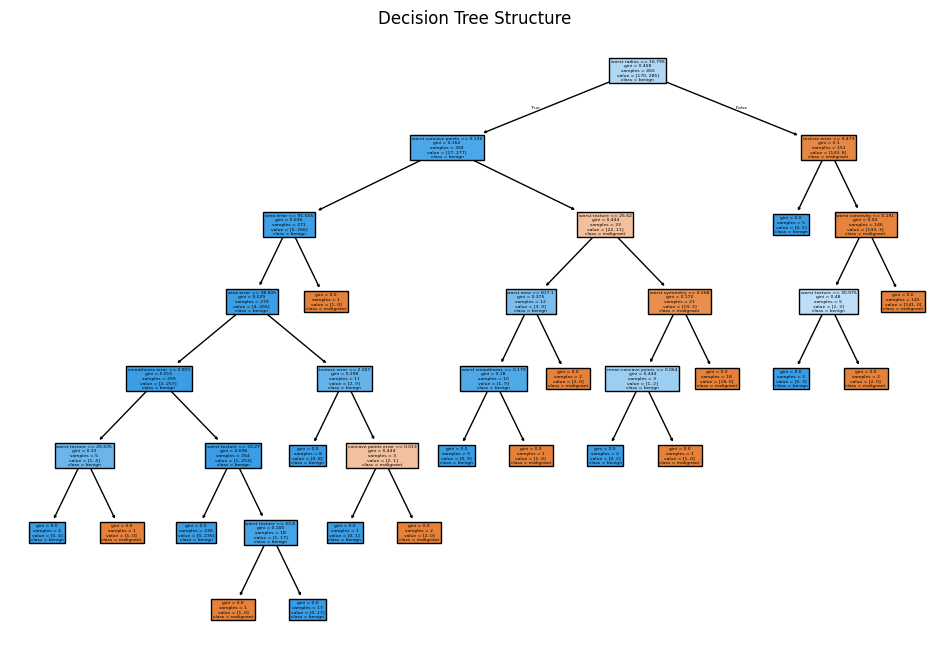

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(12,8))
plot_tree (model_dt, feature_names=X.columns,
class_names=['malignant', 'benign'],
filled=True)
plt.title("Decision Tree Structure")
plt.show()

In [ ]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [ ]:
model_dt_pca = DecisionTreeClassifier (random_state=42).fit(X_train_pca, y_train)

In [ ]:
x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))
Z = model_dt_pca.predict(np.c_ [xx.ravel(), yy.ravel()]).reshape(xx.shape)

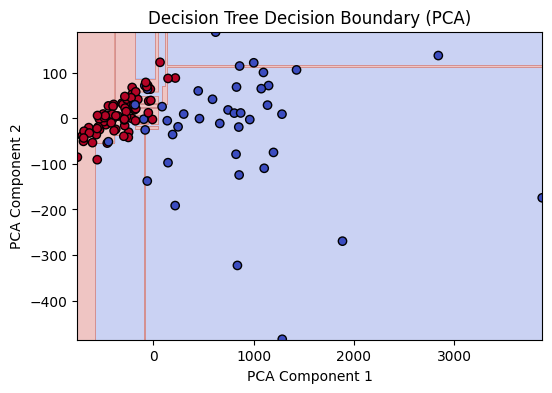

In [ ]:
plt.figure(figsize=(6, 4))
plt.contourf (xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='coolwarm', edgecolors='k')
plt.title("Decision Tree Decision Boundary (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

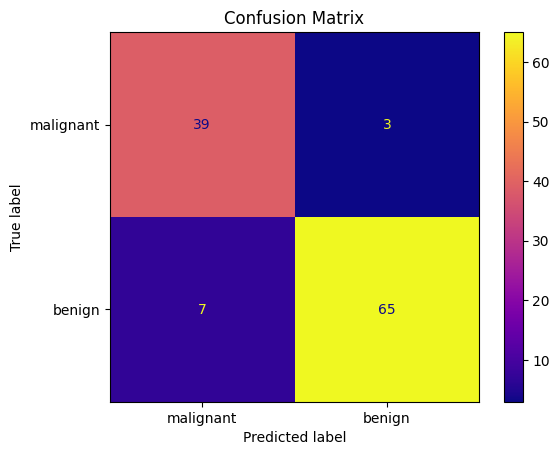

In [ ]:
cm = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay (confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap=plt.cm.plasma)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
for depth in [1, 3, 10]:
  model_dt = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
  y_pred_dt = model_dt.predict(X_test)
  print(f"Decision Tree (max_depth={depth}) Metrics:")
  print(f"Accuracy: {accuracy_score(y_test, y_pred_dt): .2f}, F1: {f1_score (y_test, y_pred_dt):.2f}")

Decision Tree (max_depth=1) Metrics:
Accuracy:  0.92, F1: 0.94
Decision Tree (max_depth=3) Metrics:
Accuracy:  0.94, F1: 0.95
Decision Tree (max_depth=10) Metrics:
Accuracy:  0.91, F1: 0.93
